<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Major League Baseball Data](https://github.com/Query-farm/vgi-mlb)

MLB standings and batting, pitching, and fielding statistics as SQL tables.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-mlb/blob/main/notebooks/02_separate_hits_from_extra_bases.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-mlb/blob/main/notebooks/README.md)


## Separate hits from extra bases

When two hitters have similar batting averages, how much of their slugging comes from extra bases? Reconstruct both rates from counts, reconcile the advanced isolated-power field, and then change the workload requirement.

**Real public MLB responses, recorded independently on 2026-11-15 UTC.**
The default replays unchanged response bodies through the real released worker.
These are historical observations, not a synthetic scenario or an atomic live
snapshot. The [provenance manifest](recordings/provenance.json) records exact URLs,
request parameters, acquisition times and hashes. All joins and choices remain visible SQL.

### Choose one local rule

**MIN_PA** is an inclusive local minimum from 250 to 750 plate appearances. Default 250; experiment 500. It is not the official qualified-player definition. The source pool always includes all 2025 regular-season hitters in both leagues.

In [1]:
DATA_MODE = "replay"
MIN_PA = 250  # Experiment: 500

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.51":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.51"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("mlb")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from mlb_examples import MLBExample

if type(MIN_PA) is not int or not 250 <= MIN_PA <= 750:
    raise ValueError("MIN_PA must be an integer from 250 to 750")
source = MLBExample(DATA_MODE, "batting")
theme()
session = connect(globals())
SOURCE = (
    "Recorded public MLB responses · captured 2026-11-15 UTC"
    if DATA_MODE == "replay"
    else "Live public MLB responses · independent endpoint reads"
) + " · worker v0.4.1"

### Attach the released worker

The public tag owns dependencies in an isolated Python 3.13 worker environment.
Shared base tooling leaves the kernel intact and starts UTC with an empty temporary
SQL-secret store and persistence disabled. The replay helper redirects the MLB root
to loopback, verifies response hashes and rejects requests outside this scenario.
Live mode clears inherited URL overrides and never falls back to replay.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'mlb' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-mlb@v0.4.1 vgi-mlb');

,Success


### Match two complete player-season reports

Both calls request the full bounded pool, without a SQL limit. The basic response provides at-bats and hit types; the advanced response supplies isolated power and extra-base counts. Materialize each once and join on player, season and game type. Multiple-team season totals stay at player grain; the last associated club is not an attribution rule.

In [5]:
%%sql
CREATE TABLE batting AS SELECT * FROM mlb.main.batting_stats(season:=2025,league:='MLB',qualified_only:=false,game_type:='R');
CREATE TABLE advanced AS SELECT * FROM mlb.main.advanced_batting_stats(season:=2025,league:='MLB',qualified_only:=false,game_type:='R');
CREATE TABLE measures AS
SELECT b.player_id,b.player_name,b.season,b.game_type,b.num_teams,b.team_id,
 b.plate_appearances,b.at_bats,b.hits,b.doubles,b.triples,b.home_runs,b.total_bases,
 a.plate_appearances AS advanced_pa,a.total_bases AS advanced_total_bases,
 a.extra_base_hits,a.isolated_power,a.home_runs_per_plate_appearance,
 1.0*b.hits/nullif(b.at_bats,0) AS hit_rate,
 1.0*b.total_bases/nullif(b.at_bats,0) AS slugging,
 1.0*(b.total_bases-b.hits)/nullif(b.at_bats,0) AS extra_bases_per_ab,
 b.plate_appearances>={{MIN_PA}} AND b.at_bats>0 AS selected
FROM batting b JOIN advanced a USING(player_id,season,game_type);

,Count


In [6]:
%%sql scope <<
SELECT (SELECT count(*) FROM batting) AS basic_rows,
 (SELECT count(*) FROM advanced) AS advanced_rows,count(*) AS joined_rows,
 count(*) FILTER(WHERE at_bats=0) AS zero_at_bats,
 count(*) FILTER(WHERE isolated_power IS NULL) AS missing_iso,
 count(*) FILTER(WHERE selected) AS selected_rows,
 count(*) FILTER(WHERE num_teams>1) AS multi_team_rows
FROM measures;

In [7]:
display(scope)
s = scope.iloc[0]
prose(
    f"Both reports have **{int(s.basic_rows)} players**, and the join retains **{int(s.joined_rows)} rows**. The local rule selects **{int(s.selected_rows)}**. There are **{int(s.zero_at_bats)} zero-at-bat rows** and **{int(s.missing_iso)} missing reported ISO values**; neither is filled with an invented rate."
)

,basic_rows,advanced_rows,joined_rows,zero_at_bats,missing_iso,selected_rows,multi_team_rows
0,765,765,765,92,92,309,76


Both reports have **765 players**, and the join retains **765 rows**. The local rule selects **309**. There are **92 zero-at-bat rows** and **92 missing reported ISO values**; neither is filled with an invented rate.

### Decompose slugging before ranking

Each hit contributes its first base. Doubles, triples and home runs add one, two and three extra bases. Thus `total_bases = hits + doubles + 2×triples + 3×home_runs`, and **ISO = (total_bases − hits) / at_bats**. This is the unrounded slugging rate minus the unrounded hit rate, not a subtraction of two rounded display columns. Compare to reported ISO with a 0.0005 rounding tolerance.

The chart shows the eight highest reconstructed ISO values in the selected pool, with deterministic player-ID tie breaking. Its stacked components describe bases per at-bat; the first component assigns one base to each hit. This is descriptive accounting, without park adjustment, uncertainty estimates or a prediction.

In [8]:
%%sql leaders <<
SELECT player_id,player_name,plate_appearances,at_bats,hits,total_bases,hit_rate,
 extra_bases_per_ab,slugging,isolated_power
FROM measures WHERE selected
ORDER BY extra_bases_per_ab DESC,plate_appearances DESC,player_id LIMIT 8;

,player_id,player_name,plate_appearances,at_bats,hits,total_bases,hit_rate,extra_bases_per_ab,slugging,isolated_power
0,592450,Aaron Judge,679,541,179,372,0.330869,0.356747,0.687616,0.357
1,663728,Cal Raleigh,705,596,147,351,0.246644,0.342282,0.588926,0.342
2,660271,Shohei Ohtani,727,611,172,380,0.281506,0.340426,0.621931,0.340
3,701762,Nick Kurtz,489,420,122,260,0.290476,0.328571,0.619048,0.329
4,656941,Kyle Schwarber,724,604,145,340,0.240066,0.322848,0.562914,0.323
5,519317,Giancarlo Stanton,281,249,68,148,0.273092,0.321285,0.594378,0.321
6,662139,Daulton Varsho,271,248,59,136,0.237903,0.310484,0.548387,0.310
7,553993,Eugenio Suárez,657,588,134,309,0.227891,0.297619,0.525510,0.298


The displayed ISO leader is **Aaron Judge**: **193 extra bases / 541 at-bats = 0.357 ISO**, added to **0.331 first bases per at-bat**. The sum is **0.688 slugging**, not OPS.

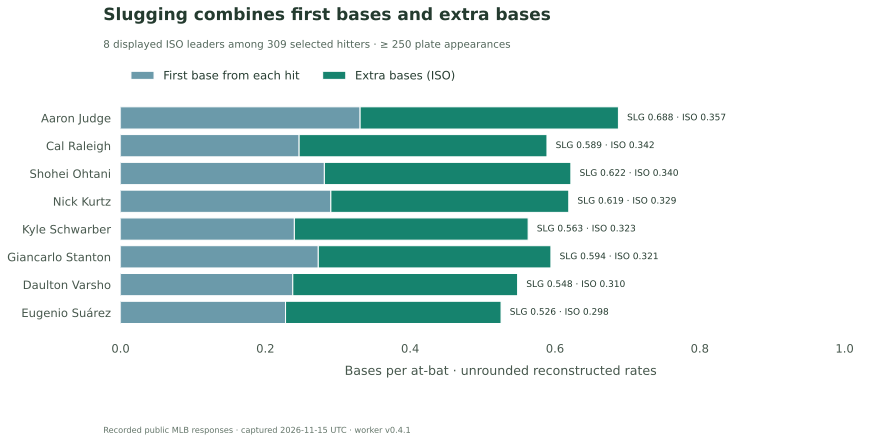

In [9]:
display(leaders)
fig, ax = plt.subplots(figsize=(12, 6.5))
if len(leaders):
    y = np.arange(len(leaders))
    ax.barh(y, leaders.hit_rate, label="First base from each hit", color="#6b9aaa")
    ax.barh(y, leaders.extra_bases_per_ab, left=leaders.hit_rate, label="Extra bases (ISO)", color="#16836e")
    for i, r in enumerate(leaders.itertuples()):
        ax.text(
            r.slugging + 0.012,
            i,
            f"SLG {r.slugging:.3f} · ISO {r.extra_bases_per_ab:.3f}",
            va="center",
            fontsize=9,
        )
    ax.set_yticks(y, leaders.player_name)
    ax.invert_yaxis()
    ax.set_xlim(0, 1.05)
    ax.set_xlabel("Bases per at-bat · unrounded reconstructed rates")
    ax.legend(loc="upper left", bbox_to_anchor=(0, 1.15), ncol=2, frameon=False)
    top = leaders.iloc[0]
    prose(
        f"The displayed ISO leader is **{top.player_name}**: **{int(top.total_bases - top.hits)} extra bases / {int(top.at_bats)} at-bats = {top.extra_bases_per_ab:.3f} ISO**, added to **{top.hit_rate:.3f} first bases per at-bat**. The sum is **{top.slugging:.3f} slugging**, not OPS."
    )
else:
    ax.text(
        0.5, 0.5, "No hitter meets the local workload rule", ha="center", va="center", transform=ax.transAxes
    )
    ax.set_axis_off()
    prose("No hitter meets this workload rule; source counts and rates are unchanged.")
finish(
    fig,
    title="Slugging combines first bases and extra bases",
    subtitle=f"{len(leaders)} displayed ISO leaders among {int(scope.selected_rows.iloc[0])} selected hitters · ≥ {MIN_PA} plate appearances",
    source=SOURCE,
    name=f"slugging-components-{MIN_PA}",
)

### Keep the full selected population in view

A high batting average need not imply equally high isolated power: these count different things. Plot all selected hitters, highlighting the eight from the preceding table. Fixed axes make the workload experiment comparable. Marker locations are observed season rates; no fitted line or causal claim is added.

In [10]:
%%sql population <<
SELECT player_id,player_name,plate_appearances,hit_rate,extra_bases_per_ab,selected
FROM measures ORDER BY player_id;

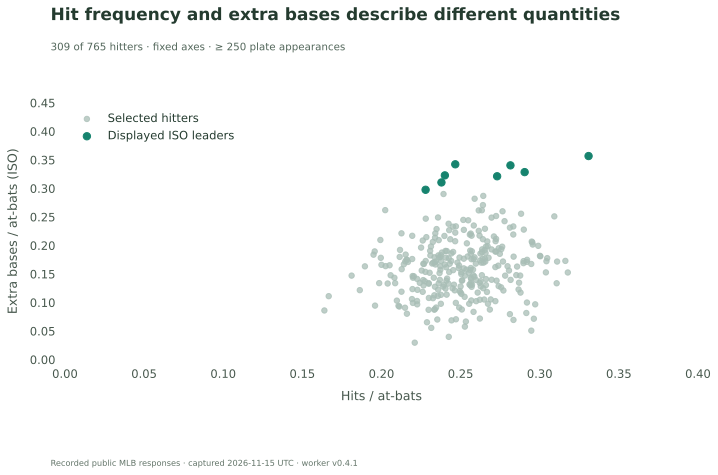

The cloud contains **309 selected player-season rows**, including the **8 displayed ISO leaders**. Raising the minimum changes membership and possibly the named leaders; it never moves an individual player's rate coordinates.

In [11]:
p = population[population.selected]
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(p.hit_rate, p.extra_bases_per_ab, s=30, color="#a8bdb5", alpha=0.75, label="Selected hitters")
ax.scatter(leaders.hit_rate, leaders.extra_bases_per_ab, s=55, color="#16836e", label="Displayed ISO leaders")
ax.set(xlim=(0, 0.4), ylim=(0, 0.45), xlabel="Hits / at-bats", ylabel="Extra bases / at-bats (ISO)")
ax.legend(loc="upper left", frameon=False)
if len(p) == 0:
    ax.text(
        0.5, 0.5, "No hitter meets the local workload rule", ha="center", va="center", transform=ax.transAxes
    )
finish(
    fig,
    title="Hit frequency and extra bases describe different quantities",
    subtitle=f"{len(p)} of {len(population)} hitters · fixed axes · ≥ {MIN_PA} plate appearances",
    source=SOURCE,
    name=f"hits-versus-power-{MIN_PA}",
)
prose(
    f"The cloud contains **{len(p)} selected player-season rows**, including the **{len(leaders)} displayed ISO leaders**. Raising the minimum changes membership and possibly the named leaders; it never moves an individual player's rate coordinates."
)

In [12]:
%%sql checks <<
SELECT 'unique basic player pool' AS check_name,count(*)=count(DISTINCT player_id) AND count(*)>0 AS passed FROM batting
UNION ALL SELECT 'unique advanced player pool',count(*)=count(DISTINCT player_id) AND count(*)>0 FROM advanced
UNION ALL SELECT 'join retains complete pools',(SELECT count(*) FROM measures)=(SELECT count(*) FROM batting) AND (SELECT count(*) FROM measures)=(SELECT count(*) FROM advanced)
UNION ALL SELECT 'season and game type fixed',bool_and(season=2025 AND game_type='R') FROM measures
UNION ALL SELECT 'advanced exposures and bases reconcile',bool_and(plate_appearances=advanced_pa AND total_bases=advanced_total_bases) FROM measures
UNION ALL SELECT 'total bases reconstruct from hit types',bool_and(total_bases=hits+doubles+2*triples+3*home_runs) FROM measures
UNION ALL SELECT 'extra-base counts reconcile',bool_and(extra_base_hits=doubles+triples+home_runs) FROM measures
UNION ALL SELECT 'ISO agrees within rounding',count(*)=0 FROM measures WHERE isolated_power IS NOT NULL AND extra_bases_per_ab IS NOT NULL AND abs(CAST(isolated_power AS DOUBLE)-extra_bases_per_ab)>.000500001
UNION ALL SELECT 'slugging equals component sum',count(*)=0 FROM measures WHERE abs(slugging-hit_rate-extra_bases_per_ab)>1e-12
UNION ALL SELECT 'zero denominators remain unavailable',count(*)=0 FROM measures WHERE at_bats=0 AND (hit_rate IS NOT NULL OR extra_bases_per_ab IS NOT NULL)
UNION ALL SELECT 'home-run fraction uses plate appearances',count(*)=0 FROM measures WHERE plate_appearances>0 AND home_runs_per_plate_appearance IS NOT NULL AND abs(CAST(home_runs_per_plate_appearance AS DOUBLE)-1.0*home_runs/plate_appearances)>.000500001
UNION ALL SELECT 'multi-team totals stay unattributed',count(*)=0 FROM measures WHERE num_teams>1 AND team_id IS NOT NULL;

In [13]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + source.audit())
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-02.json").write_text(
    json.dumps(
        {
            "parameters": {"DATA_MODE": DATA_MODE, "MIN_PA": MIN_PA},
            "scope": scope.to_dict("records"),
            "leaders": leaders.to_dict("records"),
            "population": population.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,unique basic player pool,True
1,unique advanced player pool,True
2,join retains complete pools,True
3,season and game type fixed,True
4,advanced exposures and bases reconcile,True
5,total bases reconstruct from hit types,True
6,extra-base counts reconcile,True
7,ISO agrees within rounding,True
8,slugging equals component sum,True
9,zero denominators remain unavailable,True


**All 12 SQL checks passed.** Exactly 2 recorded responses requested once each; no unexpected requests.

167187

### Change one thing

Change **MIN_PA from 250 to 500**. Predict fewer eligible hitters; inspect whether the displayed ISO names change. All raw counts, reconstructed coordinates and source request audit must remain identical. **750** is a separate empty-selection boundary for this recording; it still displays full-source diagnostics without inventing leaders. Restore 250 for the saved default.

In [14]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-mlb](https://github.com/Query-farm/vgi-mlb)